<div align="center">

UNIVERSITÉ DE LIÈGE<br>
FACULTÉ DES SCIENCES APPLIQUÉES<br>
DÉPARTEMENT ArGEnCo

<br>

# Projet — partim Volumes Finis

### Résolution d'un labyrinthe par advection pure

<br>

**JOSEPH KIBEYA NDOFULA**

<br>

GCVIV0185-7 — Méthodes numériques linéaires en génie civil et géologique<br>
ANNÉE ACADÉMIQUE 2026–2027

</div>

---

## Objet du travail

Nous résolvons le parcours d'un labyrinthe en y faisant circuler un écoulement, puis en
suivant un constituant transporté par cet écoulement. Le champ de vitesses dérive d'un
potentiel obtenu par différences finies ; le transport du constituant est résolu par la
méthode des volumes finis, dans deux versions que nous comparons :

| | Reconstruction | Schéma temporel | Ordre attendu |
|---|---|---|---|
| **Version A** | constante | Euler explicite | 1 |
| **Version B** | linéaire | Runge-Kutta à 2 pas | 2 |

L'équation résolue est celle d'un constituant purement advecté :

$$\frac{\partial c}{\partial t} + u\,\frac{\partial c}{\partial x} + v\,\frac{\partial c}{\partial y} = 0$$

## Plan

Nous avons divisé ce travail en quatre parties.

1. **La construction du champ de vitesses** : de l'image du labyrinthe aux vitesses sur
   chaque face, les conditions aux limites, et la précision de ces vitesses déduites.
2. **La validation** : les tests sur canal rectiligne, la mesure de l'ordre de
   convergence, le bilan de masse, et un défaut de condition limite trouvé puis corrigé.
3. **L'application** au labyrinthe : les quatre cas calculés, les figures et les vidéos.
4. **L'analyse critique** : la diffusion numérique, les dépassements et le théorème de
   Godunov, le coût de calcul et les limites du travail.

## Hypothèses et conventions

Ces choix valent pour tout le document.

| Élément | Choix retenu |
|---|---|
| **Maillage** | une maille = un pixel de l'image, donc $\Delta x = \Delta y = 1$ |
| **Écoulement** | incompressible, irrotationnel, et **permanent** : le champ de vitesses ne change jamais au cours du calcul |
| **Constituant** | purement advecté. L'équation ne comporte **aucun terme de diffusion** |
| **Parois** | imperméables : $\vec{V}\cdot\vec{n} = 0$ |
| **Position** | convention matricielle. L'élément $[0,0]$ est en haut à gauche et l'indice de ligne $i$ **augmente vers le bas** : $u > 0$ va vers la droite, $v > 0$ va **vers le bas** |
| **Nombre de Courant** | $\nu = 0{,}80$, choix justifié en partie 3.1 |
| **Potentiel** | calculé par le solveur fourni, utilisé sans modification |

Le pas d'espace mérite un mot. Le domaine de calcul est directement l'image du
labyrinthe, et chaque maille correspond à **un pixel**. Les pixels étant carrés et tous
identiques, les deux pas valent la même chose, et nous les prenons comme unité de
longueur : $\Delta x = \Delta y = 1$.

Ce choix allège considérablement l'écriture. Les divisions par le pas d'espace
disparaissent des formules : une différence de potentiel entre deux mailles voisines
*est* la vitesse, un écart entre deux flux *est* la variation de concentration. Les
expressions du code se lisent alors directement comme les bilans physiques qu'elles
traduisent.

Les fonctions acceptent néanmoins des pas quelconques en argument, et les tests de
convergence de la partie 2.2 s'en servent : ils font varier $\Delta x$ pour mesurer
l'ordre du schéma.

## Exécution

Le notebook relit par défaut les résultats enregistrés dans `resultats/` et s'exécute en
quelques secondes. Pour tout recalculer depuis zéro, mettre `RELANCER = True` dans la
cellule suivante : environ 75 s pour les quatre cas, 2 min de plus pour les vidéos.

Les paquets suivants sont **nécessaires à l'exécution du code** : `numpy` pour tous les
champs, `pillow` pour la lecture et l'écriture de l'image, `matplotlib` pour les figures,
`scipy` pour le solveur fourni, `tqdm` pour les barres de progression, et
`imageio-ffmpeg` pour l'assemblage des vidéos. Ils s'installent en une commande :

    pip install -r requirements.txt

In [1]:
import os
import sys

# Les modules du projet vivent dans src/. Ce notebook est a la racine du depot.
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import numpy as np

import vitesses as V
import advection as A
import simulation_labyrinthe as S
import figures as F

from IPython.display import Image, Video, display

# ---------------------------------------------------------------------
# Mettre True pour tout recalculer depuis zero.
#   False : le notebook relit resultats/ et s'execute en quelques secondes.
#   True  : environ 75 s pour les quatre cas, 2 min de plus pour les videos.
# ---------------------------------------------------------------------
RELANCER = False

print("numpy       ", np.__version__)
print("dossier     ", os.getcwd())
print("modules     ", "vitesses, advection, simulation_labyrinthe, figures")
print("RELANCER    ", RELANCER)

numpy        2.5.3
dossier      c:\Users\josep\OneDrive\Documents\GitHub\TP1
modules      vitesses, advection, simulation_labyrinthe, figures
RELANCER     False


---
# Partie 1 — Construction du champ de vitesses

**Objectif :** transformer l'image du labyrinthe en un champ de vitesses défini sur chaque
face du maillage, traiter les faces où la formule ne s'applique pas, et établir la
précision de ces vitesses.

La donnée de départ est une image en noir et blanc : elle définit à la fois la géométrie
du labyrinthe et la largeur relative de ses bras. Toute la chaîne de calcul en découle.

La chaîne complète est une suite de quatre transformations :

    image PNG  →  potentiel φ  →  vitesses aux faces  →  advection du constituant
       (1.1)        (1.2)             (1.3 et 1.4)              (partie 3)

## 1.1 La donnée de départ : une image

Noir = mur, blanc = zone d'écoulement. L'entrée est une ouverture sur la ligne du haut,
la sortie une ouverture sur la ligne du bas, conformément au format attendu par le
solveur fourni.

Ce labyrinthe n'est pas celui fourni en exemple : il est **généré** par
`src/genere_labyrinthe.py`. Ce choix répond d'abord à une contrainte de temps de calcul.

En réduisant le nombre de pixels, nous réduisons simultanément le nombre de mailles et la
longueur du chemin à parcourir, donc le nombre de pas de temps nécessaires. Le coût total
chute, et le calcul complet peut être relancé aussi souvent qu'il le faut pendant la mise
au point — ce qui s'est révélé déterminant pour détecter les défauts décrits en partie 2.

Deux autres raisons s'y ajoutent : vérifier que le moteur de calcul ne dépend pas d'un
labyrinthe particulier, et disposer de plusieurs jeux de données.

Enfin, le générateur est **déterministe** : la graine du tirage aléatoire est fixée à 11.
Relancer le générateur réécrit donc exactement la même image, pixel pour pixel, qui vient
écraser une image identique.

C'est une précaution délibérée. Un générateur aléatoire produirait un labyrinthe différent
à chaque exécution, et le potentiel, les vitesses et tous les résultats enregistrés
deviendraient incohérents avec la nouvelle image. Ici, relancer le générateur par mégarde
est sans conséquence.

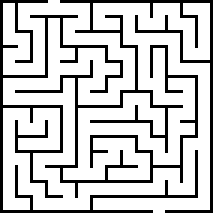

data/laby14_maze.png   -   l'entree est en haut, la sortie en bas


In [2]:
display(Image("data/laby14_maze.png", width=340))
print("data/laby14_maze.png   -   l'entree est en haut, la sortie en bas")

## 1.2 De l'image au potentiel

Cette étape est acquise sans programmation personnelle : le solveur nous est fourni.

Le dossier `laplace_prof/` est donc utilisé tel quel, **sans une ligne modifiée**, et ses
deux fichiers de sortie sont lus en lecture seule.

Le dossier `laplace_prof/` est utilisé tel quel, **sans une ligne modifiée**, et ses deux
fichiers de sortie sont lus en lecture seule. La méthode de résolution du laplacien n'est
donc pas commentée ici : elle n'est pas de moi.

**Ce que j'en retiens, et c'est tout ce dont j'ai besoin pour la suite :** la vitesse
dérive de ce potentiel,

$$\vec{V} = -\nabla \varphi
\qquad\text{soit}\qquad
u = -\frac{\partial \varphi}{\partial x}, \quad v = -\frac{\partial \varphi}{\partial y}$$

C'est de cette seule relation que part **mon** travail : transformer un champ de
potentiel en vitesses sur les faces (1.3), discuter leur précision (1.4), et traiter les
faces où la formule ne s'applique pas (1.5).

**Un point à garder en tête pour la suite.** Aux parois, une *vitesse* nulle est imposée,
puisque les murs sont imperméables. À l'entrée et à la sortie, c'est au contraire le
*potentiel* qui est imposé, à $+100$ et $-100$ : c'est ce différentiel qui met le fluide
en mouvement.

Les deux frontières ne sont donc pas traitées de la même manière, et il en résulte que la
vitesse à l'entrée n'est pas une donnée du problème : c'est un **résultat à déduire**.
C'est l'objet de la section 1.5.

In [3]:
# S.prepare fait tout l'enchainement, dans le bon ordre :
#   1. lecture du potentiel et du domaine (fichiers fournis, en lecture seule)
#   2. vitesses aux faces par differences finies
#   3. annulation des vitesses sur les faces de mur
#   4. correction des faces d'entree et de sortie
#   5. calcul du pas de temps admissible
domain, u_bord, v_bord, dt, infos = S.prepare("laby14")

ni, nj = domain.shape
print("domaine            %d x %d mailles" % (ni, nj))
print("dont fluide        %d mailles" % infos["mailles_fluides"])
print()
print("Le solveur fourni marque chaque maille :")
for valeur, sens in ((0, "mur, ou contour ajoute autour de l'image"),
                     (1, "ecoulement"),
                     (2, "entree ou sortie, condition forte sur phi")):
    print("   domain == %d   %-45s %6d mailles"
          % (valeur, sens, int((domain == valeur).sum())))

domaine            215 x 215 mailles
dont fluide        35316 mailles

Le solveur fourni marque chaque maille :
   domain == 0   mur, ou contour ajoute autour de l'image       10909 mailles
   domain == 1   ecoulement                                     35292 mailles
   domain == 2   entree ou sortie, condition forte sur phi         24 mailles


## 1.3 Du potentiel aux vitesses, sur les **faces**

Les potentiels sont donnés **au centre** des mailles. Les vitesses, elles, sont calculées
**sur les faces**, entre deux centres voisins :

$$u_{i,j+1/2} = -\frac{\varphi_{i,j+1} - \varphi_{i,j}}{\Delta x}
\qquad\qquad
v_{i+1/2,j} = -\frac{\varphi_{i+1,j} - \varphi_{i,j}}{\Delta y}$$

### La convention de position, à ne pas confondre

La convention est **matricielle** : l'élément $[0,0]$ est en haut à gauche, et l'indice de
ligne $i$ **augmente vers le bas**. Donc :

- $u > 0$ : l'écoulement va vers la **droite** ;
- $v > 0$ : l'écoulement va vers le **bas**.

C'est contre-intuitif par rapport à un repère mathématique habituel, et c'est une source
d'erreur classique. Le $v$ positif descend.

In [4]:
fluide = (domain > 0)
print("vitesses aux faces")
print("   u_bord  %s   faces verticales   (entre [i,j] et [i,j+1])" % (u_bord.shape,))
print("   v_bord  %s   faces horizontales (entre [i,j] et [i+1,j])" % (v_bord.shape,))
print()
print("   |u| max  %.4f" % infos["u_max"])
print("   |v| max  %.4f" % infos["v_max"])
print()
print("Il y a une face de moins qu'il n'y a de mailles dans la direction concernee :")
print("   %d colonnes de mailles  ->  %d faces verticales" % (nj, u_bord.shape[1]))
print("   %d lignes   de mailles  ->  %d faces horizontales" % (ni, v_bord.shape[0]))

vitesses aux faces
   u_bord  (215, 214)   faces verticales   (entre [i,j] et [i,j+1])
   v_bord  (214, 215)   faces horizontales (entre [i,j] et [i+1,j])

   |u| max  0.5746
   |v| max  0.5796

Il y a une face de moins qu'il n'y a de mailles dans la direction concernee :
   215 colonnes de mailles  ->  214 faces verticales
   215 lignes   de mailles  ->  214 faces horizontales


## 1.4 La précision de ces vitesses

Les vitesses ne sont pas des données : elles sont obtenues par une différence de
potentiel, donc par une approximation. Il est nécessaire d'en connaître la précision, afin
de savoir si elles tendent rapidement vers la valeur exacte lorsque le maillage se
raffine, ou si elles s'en approchent trop lentement pour être utilisables.

Nous le mesurons sur une fonction dont la dérivée exacte est connue, $\varphi(x) = x^3$,
dont la dérivée en $x = 2$ vaut exactement $12$. Nous estimons cette dérivée de deux
manières, en faisant varier le pas $h$ :

- **centrée sur la face**, en évaluant $\varphi$ en $x - h/2$ et $x + h/2$ — c'est la
  formule effectivement employée dans le code ;
- **calée sur le nœud**, en évaluant $\varphi$ en $x$ et $x + h$ — la même différence,
  mais prise entre le point et son voisin plutôt que symétriquement autour du bord.

La seconde ne sert qu'à la comparaison : elle n'est utilisée nulle part dans le calcul.
Nous divisons ensuite $h$ par deux et observons **de combien l'erreur diminue**.

In [5]:
phi = lambda s: s ** 3
x = 2.0
exacte = 3 * x ** 2          # derivee exacte de x^3 en x = 2

print("derivee exacte en x = 2 :  %.4f" % exacte)
print()
print("%8s %14s %10s %14s %10s" % ("h", "erreur face", "ratio", "erreur noeud", "ratio"))
print("-" * 62)

e_face_prec = e_noeud_prec = None
for h in (1.0, 0.5, 0.25, 0.125):
    # formule centree SUR LA FACE : on evalue a +h/2 et -h/2
    e_face = abs((phi(x + h / 2) - phi(x - h / 2)) / h - exacte)
    # la meme difference, mais calee sur le noeud : decentree
    e_noeud = abs((phi(x + h) - phi(x)) / h - exacte)

    r_f = "-" if e_face_prec is None else "%6.2f" % (e_face_prec / e_face)
    r_n = "-" if e_noeud_prec is None else "%6.2f" % (e_noeud_prec / e_noeud)
    print("%8.3f %14.6f %10s %14.6f %10s" % (h, e_face, r_f, e_noeud, r_n))
    e_face_prec, e_noeud_prec = e_face, e_noeud

print()
print("Quand on divise h par 2 :")
print("   l'erreur SUR LA FACE est divisee par 4  ->  ordre 2")
print("   l'erreur AU NOEUD    est divisee par 2  ->  ordre 1")

derivee exacte en x = 2 :  12.0000

       h    erreur face      ratio   erreur noeud      ratio
--------------------------------------------------------------
   1.000       0.250000          -       7.000000          -
   0.500       0.062500       4.00       3.250000       2.15
   0.250       0.015625       4.00       1.562500       2.08
   0.125       0.003906       4.00       0.765625       2.04

Quand on divise h par 2 :
   l'erreur SUR LA FACE est divisee par 4  ->  ordre 2
   l'erreur AU NOEUD    est divisee par 2  ->  ordre 1


### Ce que ce tableau dit

**Divisée par 4, pas par 2.** C'est la signature d'un ordre 2 : si l'erreur était
proportionnelle à $h$, diviser $h$ par deux diviserait l'erreur par deux. Elle est
divisée par quatre, donc elle est proportionnelle à $h^2$.

**Et la raison tient en une phrase.** La différence est centrée **sur la face** : les deux
valeurs sont prises symétriquement, à $-h/2$ et $+h/2$. En les soustrayant, les termes
d'ordre pair du développement s'annulent — en particulier le terme en $\varphi''$, qui
serait l'erreur dominante. Calée sur un nœud, la même différence n'est plus symétrique,
le terme en $\varphi''$ survit, et on retombe à l'ordre 1. C'est exactement ce que
montrent les deux colonnes.

### Pourquoi cette précision-là compte pour tout le reste du projet

C'est le vrai enjeu de la discussion demandée, et il n'est pas évident.

Les vitesses alimentent le schéma d'advection. Or l'erreur totale d'un calcul est la
**somme** de ses erreurs, et c'est **la moins bonne qui commande**. Si les vitesses
n'étaient précises qu'à l'ordre 1, elles plafonneraient tout le calcul à l'ordre 1 —
et la reconstruction linéaire employée dans notre **version B** — celle qui associe
reconstruction linéaire et schéma de Runge-Kutta à deux pas — ne servirait **strictement à
rien**, alors qu'elle demande près de deux fois plus de temps de calcul.

Autrement dit : c'est parce que les vitesses sont d'ordre 2 que la version B a un sens.
La mesure de la partie 2.2, qui trouve un ordre de 1,93 pour B sur le schéma complet, le
confirme a posteriori : rien en amont ne vient brider l'ordre 2.

### Une conséquence à retenir pour la partie 4

L'équation que nous résolvons,

$$\frac{\partial c}{\partial t} + u\,\frac{\partial c}{\partial x} + v\,\frac{\partial c}{\partial y} = 0$$

ne comporte **aucun terme de diffusion** : il n'y a pas de $D\,\nabla^2 c$ au second
membre. Le constituant est purement advecté.

Ce choix se retrouve dans la structure du code : un terme de diffusion ferait intervenir
une dérivée seconde, qui s'obtient en **additionnant** deux voisines symétriques. Or dans
tout ce code, deux voisines ne sont jamais additionnées, uniquement soustraites.

Par conséquent, toute diffusion observée dans les résultats sera nécessairement
**numérique**, et c'est ce qui la rend mesurable.

## 1.5 Les conditions aux limites du champ de vitesses

Trois familles de faces, trois traitements.

**Les faces intérieures.** La formule de différence finie s'applique directement.

**Les faces de mur.** La paroi est imperméable, donc $\vec{V}\cdot\vec{n} = 0$ : on y met
une vitesse nulle.

**Les faces d'entrée et de sortie.** Là, rien n'est donné. C'est le *potentiel* qui est
imposé à l'entrée et à la sortie, pas la vitesse. Il faut donc **déduire** la vitesse qui traverse l'ouverture,
et le seul principe disponible est la conservation de la masse : la divergence doit être
nulle dans la maille d'entrée. En écrivant ce bilan pour une maille d'entrée :

$$v_{\text{haut}} = v_{\text{bas}} + \frac{\Delta y}{\Delta x}\,(u_{\text{droite}} - u_{\text{gauche}})$$

Ce sont ces faces-là que corrige `vitesses_entree_sortie`.

### La vérification qui prouve que tout est cohérent

L'écoulement est permanent : la quantité d'eau contenue dans le labyrinthe ne varie pas
au cours du temps, donc

$$\frac{\partial}{\partial t}\int_{\Omega} \rho \, d\Omega = 0$$

Comme le fluide est de plus incompressible, il ne peut ni s'accumuler ni se raréfier
nulle part. Il s'ensuit que **le débit entrant doit être exactement égal au débit
sortant**. C'est un test global, qui porte sur l'ensemble du domaine et ne peut pas
réussir par hasard.

In [6]:
print("mailles d'entree et de sortie   %d" % infos["nb_mailles_entree_sortie"])
print("faces corrigees                 %d" % infos["nb_faces_corrigees"])
print("faces u / v valides             %d / %d"
      % (infos["faces_u_valides"], infos["faces_v_valides"]))
print()
print("debit entrant   %.6f" % infos["debit_entrant"])
print("debit sortant   %.6f" % infos["debit_sortant"])
print("ecart           %.2e" % infos["ecart_entrant_sortant"])
print()
ecart_relatif = abs(infos["ecart_entrant_sortant"]) / infos["debit_entrant"]
print("ecart relatif   %.2e   ->   %s"
      % (ecart_relatif,
         "entree = sortie, le champ est conservatif"
         if ecart_relatif < 1e-9 else "A VERIFIER"))

mailles d'entree et de sortie   24
faces corrigees                 24
faces u / v valides             33858 / 33819

debit entrant   3.001881
debit sortant   3.001881
ecart           6.02e-11

ecart relatif   2.00e-11   ->   entree = sortie, le champ est conservatif


---
# Partie 2 — Validation

**Objectif :** établir, par des critères chiffrés et non par l'apparence des images, que
le code réalise bien le schéma annoncé.

Un résultat n'a de valeur que s'il est validé. Nous entendons par là : avec un critère
chiffré, fixé **avant** de regarder le résultat, et non par l'impression que l'image
paraît correcte.

Quatre validations, de la plus simple à la plus sévère :

| | Ce qu'on teste | Sur quoi |
|---|---|---|
| 2.1 | conservation, translation exacte, murs imperméables | un canal droit |
| 2.2 | l'**ordre** réellement atteint par chaque version | un cas à solution exacte connue |
| 2.3 | le bilan de masse | le vrai labyrinthe |
| 2.4 | un défaut trouvé, expliqué, prédit, corrigé | l'injection continue |

## 2.1 Le canal rectiligne

Avant d'aborder le labyrinthe, nous éprouvons le moteur de calcul sur un cas dont la
solution exacte peut être établie **à la main**, avec une feuille, un stylo et une
calculatrice : un canal droit, formé d'une seule ligne d'eau entre deux lignes de mur,
parcouru par une vitesse uniforme.

L'intérêt est double. D'une part, la solution exacte y est une simple translation, donc
toute déformation observée est imputable au schéma. D'autre part, les valeurs choisies
font tomber tous les nombres sur des moitiés, de sorte que chaque pas de temps est
vérifiable mentalement. Une fonction erronée est introuvable dans le labyrinthe complet ;
elle se repère immédiatement ici.

Quatre propriétés y sont vérifiables sans calculatrice :

1. **la masse se conserve**. Le test suit deux quantités : l'encre encore présente dans
   le canal, et l'encre déjà sortie par l'extrémité aval. Cette seconde quantité est
   récupérée à chaque pas par la fonction qui applique les conditions aux limites : ce
   qu'elle retire du domaine, elle le comptabilise. Leur somme doit rester constante ;
2. **à $\nu = 1$ exactement, la translation est exacte** — le bloc se déplace d'une maille
   par pas, sans se déformer du tout. C'est un cas limite remarquable, dont
   l'explication est donnée en partie 4 ;
3. **les murs sont imperméables** : aucune encre ne doit apparaître dans les lignes de mur ;
4. **l'appariement des versions** : reconstruction constante avec Euler, reconstruction
   linéaire avec RK2, et pas les combinaisons croisées.

Ce même canal sert aussi à vérifier qu'on utilise bien le moteur 2D du projet, et pas un
code à part : les tests appellent exactement les mêmes fonctions que le labyrinthe.

In [7]:
import runpy

# On execute le fichier de tests comme s'il etait lance en ligne de commande.
# `run_path` renvoie le dictionnaire des variables du script : on le range dans
# une variable, sinon le notebook l'afficherait en entier sous la cellule.
_variables_du_test = runpy.run_path(
    os.path.join("src", "test_advection_canal_rectiligne.py"),
    run_name="__main__")

TEST 1 - CANAL RECTILIGNE : la masse est-elle conservee ?
  depart : [  0. 100. 100.   0.   0.   0.   0.]   masse = 200.00
  pas 1 : [  0.  50. 100.  50.   0.   0.   0.]   dans= 200.00  sorti=  0.00  TOTAL= 200.00
  pas 2 : [ 0. 25. 75. 75. 25.  0.  0.]   dans= 200.00  sorti=  0.00  TOTAL= 200.00
  pas 3 : [ 0.  12.5 50.  75.  50.  12.5  0. ]   dans= 200.00  sorti=  0.00  TOTAL= 200.00
  pas 4 : [ 0.    6.25 31.25 62.5  62.5  31.25  6.25]   dans= 200.00  sorti=  0.00  TOTAL= 200.00
  pas 5 : [ 0.    3.12 18.75 46.88 62.5  46.88 18.75]   dans= 196.88  sorti=  3.12  TOTAL= 200.00
  pas 6 : [ 0.    1.56 10.94 32.81 54.69 54.69 32.81]   dans= 187.50  sorti= 12.50  TOTAL= 200.00
  -> ecart sur la masse totale : 0.00e+00   OK

TEST 2 - CANAL RECTILIGNE : translation EXACTE a Courant = 1
  A nu = 1, la dissipation numerique eps = u dx (1 - nu) / 2 vaut
  exactement ZERO : le bloc doit se deplacer sans se deformer.
  depart : [100. 100.   0.   0.   0.   0.   0.   0.   0.]
  apres 3 pas : [  0.

## 2.2 L'ordre de convergence, mesuré

C'est **le meilleur détecteur de bug des méthodes numériques**. La théorie affirme que ce
schéma, correctement écrit, converge à l'ordre 2 — mais elle parle du *schéma*, pas du
*code*. Une erreur d'indice ou un signe inversé laisserait le programme tourner, produire
de belles images, conserver même la masse... et converger à l'ordre 1.

Seule la mesure tranche.

### Le principe

Nous prenons un cas dont la solution exacte est **connue** : le canal droit de la section
précédente, parcouru par une vitesse uniforme, dans lequel nous déposons un profil de
concentration régulier.

Dans un tel canal, l'encre est simplement emportée sans se déformer. Si $c_0$ désigne le
profil déposé au départ et $a$ la vitesse de l'eau, alors au bout d'un temps $t$ ce profil
s'est déplacé de la distance $a\,t$, et rien d'autre ne lui est arrivé :

$$c(x,t) = c_0(x - a\,t)$$

où $x$ est la position le long du canal et $c(x,t)$ la concentration en ce point à cet
instant. Nous disposons ainsi, en chaque point et à chaque instant, de la valeur que le
calcul **devrait** donner.

On calcule sur des maillages de plus en plus fins, **à nombre de Courant constant** (donc
$\Delta t$ diminue en même temps que $\Delta x$), et on mesure l'écart à la solution
exacte en norme $L^1$ :

$$E = \frac{1}{N}\sum_i \left| c_i^{\text{calculé}} - c_i^{\text{exact}} \right|$$

Si le schéma est d'ordre $p$, alors $E \propto \Delta x^{\,p}$. Diviser $\Delta x$ par deux
divise donc $E$ par $2^p$, et l'ordre observé se lit directement :

$$p = \log_2\!\left(\frac{E(\Delta x)}{E(\Delta x/2)}\right)$$

### Pourquoi le profil de départ doit être arrondi

Le profil que nous déposons est une **gaussienne**, c'est-à-dire une bosse arrondie, aux
flancs progressifs. Ce choix n'est pas esthétique, il est nécessaire.

Le profil opposé serait un **créneau** : de l'encre à 100 sur quelques mailles, zéro juste
à côté, avec une marche verticale entre les deux. Or toute la notion d'ordre repose sur le
développement de Taylor, qui exige que la fonction soit dérivable. À l'endroit de la
marche, la pente est infinie et la dérivée n'existe pas : le développement ne s'applique
plus.

La conséquence est qu'**aucun** schéma n'atteint son ordre annoncé sur un créneau. Nous
mesurerions un ordre proche de 1 pour les deux versions, et nous en conclurions à tort que
la reconstruction linéaire n'apporte rien.

Les ordres annoncés ne valent donc que pour des solutions régulières. Il s'agit d'une
limite réelle du résultat, sur laquelle nous reviendrons en partie 4.

In [8]:
import test_convergence as TC

ordres = TC.etude()

Test de convergence  -  canal droit, gaussienne translatee
vitesse 1.0   Courant 0.80   duree simulee 0.5

A : constante + Euler        (ordre attendu : 1)
   mailles       dx      pas      erreur L1    ordre p
  ------------------------------------------------------
        80  0.01250       50   2.711423e+00          -
       160  0.00625      100   1.531219e+00       0.82
       320  0.00313      200   8.237477e-01       0.89
       640  0.00156      400   4.283552e-01       0.94
  ordre moyen observe : 0.89   (attendu 1)

B : lineaire + RK2        (ordre attendu : 2)
   mailles       dx      pas      erreur L1    ordre p
  ------------------------------------------------------
        80  0.01250       50   2.707969e+00          -
       160  0.00625      100   7.596010e-01       1.83
       320  0.00313      200   1.941799e-01       1.97
       640  0.00156      400   4.870997e-02       2.00
  ordre moyen observe : 1.93   (attendu 2)



**Lecture du résultat.**

La version A mesure un ordre proche de **1**, la version B proche de **2**, ce qui
correspond à la précision de chaque reconstruction. La reconstruction constante suppose
que la valeur moyenne vaut sur l'ensemble de la maille ; la reconstruction linéaire y
suppose une variation bilinéaire, dont les gradients directionnels sont évalués sur les
deux mailles voisines.

La règle est : **reconstruction de degré $r$ $\Rightarrow$ ordre $r+1$.**

- degré 0 (constante) $\Rightarrow$ ordre 1
- degré 1 (linéaire) $\Rightarrow$ ordre 2

L'ordre 2 de la version B n'est donc pas seulement attendu par la théorie : il est
**observé sur le code lui-même**. C'est ce qui permet d'affirmer que l'implémentation
réalise bien le schéma annoncé.

## 2.3 Le bilan de masse sur le vrai labyrinthe

Les tests précédents se font sur un canal. Celui-ci se fait sur la géométrie réelle.

### Le cas qui permet de le vérifier proprement

C'est la **tache initiale** : on pose une tache au départ, et plus rien n'entre ensuite.
On peut alors écrire le bilan en une ligne :

$$\text{masse initiale} = \text{masse restante} + \text{masse sortie}$$

**Ce que vérifie exactement la cellule ci-dessous.** Elle est volontairement courte
(600 pas) pour s'exécuter en quelques secondes. En 600 pas, la tache n'a pas encore atteint
la sortie : ce qui est vérifié ici, c'est donc la conservation **à l'intérieur** du domaine
— rien ne se perd, rien ne se crée en traversant des centaines de milliers de faces.

Le terme de sortie, lui, est validé ailleurs et de deux façons : par le **test 1 du canal
rectiligne** ci-dessus, où l'encre sort effectivement du domaine et où le total
`dans + sorti` reste à 200,00 avec un écart de `0.00e+00` ; et par l'étude complète sur
9 748 pas (section 3.2), qui imprime le bilan final des quatre cas.

In [9]:
N_COURT = 600          # assez pour que de l'encre sorte, assez court pour etre instantane

conditions, c_impose = S.fabrique_conditions(domain, c_injection=0.0)   # rien n'entre
c0 = S.tache_initiale(domain)

snaps, trace, bilan = S.simule(domain, u_bord, v_bord, dt, c0,
                               conditions, c_impose,
                               version="B", n_pas=N_COURT, bavard=False)

print("tache initiale, version B, %d pas" % N_COURT)
print()
print("   masse initiale   %14.6f" % bilan["masse_initiale"])
print("   masse restante   %14.6f" % bilan["masse_dedans"])
print("   masse sortie     %14.6f" % bilan["masse_sortie"])
print("   " + "-" * 31)
print("   ecart            %14.2e" % bilan["ecart"])
print()
relatif = abs(bilan["ecart"]) / bilan["masse_initiale"]
print("   ecart relatif    %14.2e   ->   %s"
      % (relatif, "conservation exacte" if relatif < 1e-12 else "A VERIFIER"))
print()
print("   L'ecart est de l'ordre de la precision machine (1e-16 en relatif),")
print("   apres %d pas sur %d mailles fluides." % (N_COURT, infos["mailles_fluides"]))
if bilan["masse_sortie"] == 0.0:
    print()
    print("   masse sortie = 0 : en %d pas la tache n'a pas encore atteint la" % N_COURT)
    print("   sortie. Le terme de sortie est valide par le test 1 du canal")
    print("   ci-dessus, et par l'etude complete de la section 3.2.")

B             : 100%|██████████████████████████████████| 600/600 [00:02<00:00, 241.71 pas/s]

tache initiale, version B, 600 pas

   masse initiale     18000.000000
   masse restante     18000.000000
   masse sortie           0.000000
   -------------------------------
   ecart                  3.64e-12

   ecart relatif          2.02e-16   ->   conservation exacte

   L'ecart est de l'ordre de la precision machine (1e-16 en relatif),
   apres 600 pas sur 35316 mailles fluides.


### Pourquoi ce n'est pas de la chance

Un écart de $10^{-16}$ en relatif après des centaines de milliers de passages de flux,
ce n'est pas un hasard numérique : c'est une propriété **de construction** de la méthode.

La raison tient en une phrase : **chaque face porte un flux unique**, compté en moins pour
une maille et en plus pour sa voisine. En sommant sur tout le domaine, les flux intérieurs
s'annulent deux à deux et il ne reste que les frontières.

Cette unicité n'a rien d'automatique : un bord dispose de **deux** informations
discontinues, l'une venant de la maille de gauche, l'autre de celle de droite. Le flux
retenu pour ce bord doit pourtant être unique, et c'est le décentrement amont qui tranche
entre les deux.

### Position de la méthode employée

Il est utile de rappeler d'où vient cette formulation. La méthode des volumes finis n'est
pas une recette isolée : elle correspond au cas où l'on intègre l'équation sur chaque
maille prise séparément, et c'est précisément cette intégration sur un sous-domaine qui
fait apparaître le bilan de flux, par le théorème de la divergence :

$$\int_{\Omega_i}\left[\frac{\partial c}{\partial t} + \mathrm{div}(\vec{V}c)\right]d\Omega = 0
\qquad\Longrightarrow\qquad
\frac{\partial c}{\partial t} = \frac{\text{bilan des échanges}}{S}$$

C'est donc le fait de raisonner **maille par maille**, et non point par point, qui garantit
la conservation exacte de la masse.

## 2.4 Un défaut trouvé, expliqué, prédit, puis corrigé

C'est le point le plus instructif du projet, et il n'a été trouvé que parce que le bilan
de masse était vérifié systématiquement.

### Le symptôme

En injection continue avec le schéma Runge-Kutta, la masse réellement entrée dans le
domaine valait **environ 92 %** de la masse théoriquement injectée. Avec Euler, 100 %.
Le bilan de masse, lui, restait parfait : rien ne se perdait **dans** le domaine. Le
problème était donc **à la frontière**, pas à l'intérieur.

### La cause

Un schéma Runge-Kutta à deux pas s'écrit :

$$k_1 = \mathcal{L}(c^n) \qquad c^{*} = c^n + \Delta t\,k_1 \qquad
k_2 = \mathcal{L}(c^{*}) \qquad c^{n+1} = c^n + \frac{\Delta t}{2}(k_1 + k_2)$$

Il s'agit donc d'une **double application** d'un schéma de type Euler : un premier pas
complet produit l'estimation $c^{*}$, un second l'évalue, et la moyenne des deux pentes
donne l'avancement retenu.

Le brouillon $c^{*}$ est une estimation intermédiaire, jetée aussitôt. On peut donc le
croire sans importance. **C'est faux pour la frontière.**

La condition limite est *faible* : l'encre n'est jamais écrite dans le domaine, elle
n'entre que **par le flux**, et la valeur amont de ce flux est celle de la maille
extérieure — la « citerne ».

Cette forme faible découle directement du décentrement amont : puisque le flux d'un bord
est pris du côté d'où vient le fluide, il suffit de fixer la valeur de la maille
extérieure pour imposer la condition. On n'écrit jamais dans le domaine lui-même.

Or le premier sous-pas **vidait partiellement la citerne**. Le second sous-pas voyait donc
une citerne déjà entamée et faisait entrer moins d'encre que prévu.

### La prédiction, faite *avant* de mesurer

Si $c_e = 100$ est la concentration imposée et $v_j$ les vitesses d'entrée, le premier
sous-pas abaisse la citerne à $c_e - \Delta t\,v_j\,c_e/\Delta y$. La masse entrée sur un
pas devient donc :

$$\delta m = c_e\,\Delta t \sum_j v_j \;-\; \frac{c_e\,\Delta t^2}{2}\sum_j v_j^2$$

Le second terme est le manque. Appliqué aux chiffres du cas, il prédisait **261,77** au
lieu de **284,43** — soit 92,0 %. La mesure a donné exactement cela. Le mécanisme était
donc bien compris, et pas seulement constaté.

### La correction, et la règle générale

Une seule ligne : appliquer la condition limite **aussi au brouillon**.

```python
essai = c + dt * k1
if conditions is not None:
    essai = conditions(essai)   # la frontiere est une donnee, pas une inconnue
```

> **Règle à retenir, valable pour tout schéma multi-étapes :**
> le brouillon a le droit d'être faux *à l'intérieur* du domaine — il est jeté —
> mais il n'a **jamais** le droit de modifier une *donnée* du problème.

### La démonstration, en direct

La cellule suivante lance le même calcul deux fois : une fois en passant la condition
limite au brouillon, une fois sans. Elle compare la masse entrée à la masse théorique.

In [10]:
def masse_entree(n_pas, corrige):
    # Lance n_pas d'injection continue en RK2 et renvoie la masse reellement
    # entree. `corrige` decide si la condition limite est appliquee au brouillon.
    conditions, c_impose = S.fabrique_conditions(domain, c_injection=100.0)
    dehors, alimente, evacue = S.reperage(domain)

    c = conditions(np.zeros_like(domain, dtype=float))
    entree = 0.0
    for _ in range(n_pas):
        c = A.pas_rk2(c, domain, u_bord, v_bord, dt, lineaire=True,
                      conditions=conditions if corrige else None)
        entree += -(c[alimente] - c_impose[alimente]).sum()
        c = conditions(c)
    return entree


N = 300
attendu = infos["debit_entrant"] * 100.0 * dt * N      # ce qui DOIT entrer

print("injection continue, version B (RK2), %d pas" % N)
print()
print("   masse theorique injectee          %12.2f" % attendu)
print()
for corrige, nom in ((False, "SANS la correction"), (True, "AVEC la correction")):
    obtenue = masse_entree(N, corrige)
    print("   %-34s %12.2f   =  %6.2f %% du theorique"
          % (nom, obtenue, 100.0 * obtenue / attendu))
print()
print("   Le defaut n'est pas une perte de masse : rien ne disparait dans le")
print("   domaine. C'est de l'encre qui n'est JAMAIS ENTREE.")

injection continue, version B (RK2), 300 pas

   masse theorique injectee              62419.27

   SANS la correction                     56571.42   =   90.63 % du theorique
   AVEC la correction                     62419.27   =  100.00 % du theorique

   Le defaut n'est pas une perte de masse : rien ne disparait dans le
   domaine. C'est de l'encre qui n'est JAMAIS ENTREE.


---
# Partie 3 — Application au labyrinthe

**Objectif :** calculer le transport du constituant sur le labyrinthe complet, dans les
deux versions et sur deux conditions initiales, et en produire les figures et les vidéos.

Le moteur validé, nous l'appliquons au labyrinthe.

## 3.1 Le pas de temps : la condition de Courant

Le schéma est **explicite** : la valeur au pas suivant se calcule directement à partir du
pas courant, sans résoudre de système. Cette commodité a un prix, la stabilité n'est
assurée que si le nombre de Courant reste inférieur à l'unité.

En deux dimensions, l'analyse de stabilité d'un schéma décentré amont conduit à :

$$\nu = \Delta t \left( \frac{|u|}{\Delta x} + \frac{|v|}{\Delta y} \right) \leq 1$$

Le point important pour ce projet est la **somme** : en 2D les deux directions
s'additionnent, on ne peut pas se contenter du plus petit des deux critères
unidimensionnels. Le couplage des deux directions rend donc le critère **plus restrictif**
qu'en une dimension, ce qui impose un pas de temps plus petit à maillage égal.

### Le choix du nombre de Courant

La condition de stabilité impose $\nu < 1$, rien de plus : la valeur exacte reste à notre
appréciation. Nous avons retenu $\nu = 0{,}80$, pour deux raisons.

- $\nu = 1$ est la limite exacte de stabilité : s'en approcher est risqué dès qu'une
  vitesse locale est légèrement sous-estimée ;
- la dissipation numérique vaut $\varepsilon = \dfrac{u\,\Delta x}{2}(1-\nu)$ : elle
  **diminue** quand $\nu$ augmente. Prendre $\nu$ trop petit par prudence coûterait donc à
  la fois du temps de calcul *et* de la précision.

$\nu = 0{,}80$ est le compromis : marge confortable, dissipation réduite.

L'écoulement étant **permanent**, le champ de vitesses ne change jamais : $\Delta t$ est
donc calculé **une seule fois**, au début.

In [11]:
print("pas de temps")
print("   dt              %.4f" % dt)
print("   nombre de Courant %.2f" % infos["courant"])
print()
print("verification directe de la condition CFL, maille par maille :")
print("   on cherche le maximum de  dt * ( |u|/dx + |v|/dy )  sur tout le domaine")
print()
print("   |u| max         %.4f" % infos["u_max"])
print("   |v| max         %.4f" % infos["v_max"])
print("   dt * (|u|max + |v|max) = %.4f   <= 1 : %s"
      % (dt * (infos["u_max"] + infos["v_max"]),
         dt * (infos["u_max"] + infos["v_max"]) <= 1.0))

n_pas = S.pas_necessaires(domain, u_bord, v_bord, dt, 1.5)
print()
print("nombre de pas retenu : %d" % n_pas)
print("   estime par : (volume d'eau / debit) / dt, avec une marge de 1,5")
print("   soit un temps physique de %.0f" % (n_pas * dt))

pas de temps
   dt              0.6931
   nombre de Courant 0.80

verification directe de la condition CFL, maille par maille :
   on cherche le maximum de  dt * ( |u|/dx + |v|/dy )  sur tout le domaine

   |u| max         0.5746
   |v| max         0.5796
   dt * (|u|max + |v|max) = 0.8000   <= 1 : True

nombre de pas retenu : 9748
   estime par : (volume d'eau / debit) / dt, avec une marge de 1,5
   soit un temps physique de 6756


## 3.2 Les deux cas étudiés, et pourquoi les deux

L'énoncé demande d'appliquer l'outil « sur différents jeux de données simples ». Deux cas
sont traités, et ils ne servent pas à la même chose.

| | **Injection continue** | **Tache initiale** |
|---|---|---|
| Ce qu'on fait | de l'encre entre sans arrêt par l'entrée | une tache est posée au départ, puis plus rien n'entre |
| À quoi ça sert | **le résultat** : le chemin de l'entrée à la sortie se trace tout seul | **le test** : le seul cas où le bilan de masse s'écrit en une ligne |
| Ce qu'on y lit | la résolution du labyrinthe | la conservation, et la diffusion numérique |

Chacun est calculé dans les **deux versions** :

| | Version A | Version B |
|---|---|---|
| Reconstruction | constante | linéaire |
| Schéma temporel | Euler | Runge-Kutta 2 |
| Ordre attendu | 1 | 2 |

Soit **quatre cas** au total. Ils sont totalement indépendants : aucun n'attend le
résultat d'un autre, donc ils tournent en parallèle sur des cœurs différents. Le temps
total devient celui du plus long au lieu de la somme — environ 75 s au lieu de 4 minutes.

In [12]:
if RELANCER:
    resume, dt_calcule, n_pas_calcule = S.etude_complete("laby14")

    print()
    print("BILAN DE MASSE COMPLET, sur %d pas" % n_pas_calcule)
    print("%-14s %14s %14s %14s %13s"
          % ("cas", "initiale", "entree", "sortie + dedans", "ecart"))
    print("-" * 76)
    for nom in sorted(resume):
        b = resume[nom]
        print("%-14s %14.2f %14.2f %14.2f %13.2e"
              % (nom, b["masse_initiale"], b["masse_entree"],
                 b["masse_dedans"] + b["masse_sortie"], b["ecart"]))
    print()
    print("L'ecart est  masse_initiale + entree - dedans - sortie.")
    print("Il est nul a la precision machine : le schema est conservatif.")
else:
    print("RELANCER = False  ->  on relit les resultats deja enregistres.")
    print()
    print("Pour tout recalculer : mettre RELANCER = True dans la premiere cellule,")
    print("ou lancer en ligne de commande     cd src  &&  python simulation_labyrinthe.py")
    print()
    for f in sorted(os.listdir("resultats")):
        if f.endswith(".npz") or f.endswith(".npy"):
            taille = os.path.getsize(os.path.join("resultats", f)) / 1024
            print("   resultats/%-24s %7.0f Ko" % (f, taille))

RELANCER = False  ->  on relit les resultats deja enregistres.

Pour tout recalculer : mettre RELANCER = True dans la premiere cellule,
ou lancer en ligne de commande     cd src  &&  python simulation_labyrinthe.py

   resultats/domaine_laby14.npy            45 Ko
   resultats/injection_A.npz              320 Ko
   resultats/injection_B.npz              350 Ko
   resultats/tache_A.npz                  360 Ko
   resultats/tache_B.npz                  394 Ko


## 3.3 Le bilan des quatre cas

Les nombres ci-dessous ne sont pas recopiés : ils sont **recalculés** à partir des champs
enregistrés, à chaque exécution du notebook.

In [13]:
print("%-14s %12s %12s %16s" % ("cas", "c min", "c max", "encre impasses"))
print("-" * 58)

mesures = {}
for cas in ("injection", "tache"):
    for version in ("A", "B"):
        nom = "%s_%s" % (cas, version)
        archive = F._charge(nom)
        dernier = archive["pas_%d" % max(F._instants(archive))]
        impasses = S.encre_dans_les_impasses(dernier, domain, u_bord, v_bord)
        mesures[nom] = (dernier[fluide].min(), dernier[fluide].max(), impasses)
        print("%-14s %12.2f %12.2f %14.2f %%" % ((nom,) + mesures[nom]))

print()
print("Deux choses sautent aux yeux, et elles sont discutees en partie 4 :")
print("   - la version A reste dans [0 ; 100], la version B en sort ;")
print("   - la version A met plus d'encre dans les impasses que la version B.")

cas                   c min        c max   encre impasses
----------------------------------------------------------
injection_A            0.00       100.00           0.20 %
injection_B           -5.66       105.40           0.13 %
tache_A                0.00         2.29           8.30 %
tache_B               -0.39         5.67           5.20 %

Deux choses sautent aux yeux, et elles sont discutees en partie 4 :
   - la version A reste dans [0 ; 100], la version B en sort ;
   - la version A met plus d'encre dans les impasses que la version B.


## 3.4 Les figures

Cinq figures, toutes produites par `src/figures.py` — **aucune n'est fabriquée à la main**.
La règle du dépôt est que tout ce qui se trouve dans `resultats/` est produit par du code
de `src/`.

Une remarque sur l'échelle de couleur. Pour l'injection, elle va de 0 à 100 : c'est la
valeur injectée. Pour la tache, non — rien n'entre après le départ, donc la tache se
**dilue** en avançant et son maximum tombe bien en dessous de 100. L'échelle est donc
adaptée, mais elle reste **la même pour A et pour B**, sans quoi la même couleur ne
représenterait pas la même concentration d'une figure à l'autre et la comparaison serait
trompeuse. L'échelle utilisée est écrite dans le sous-titre de chaque figure.

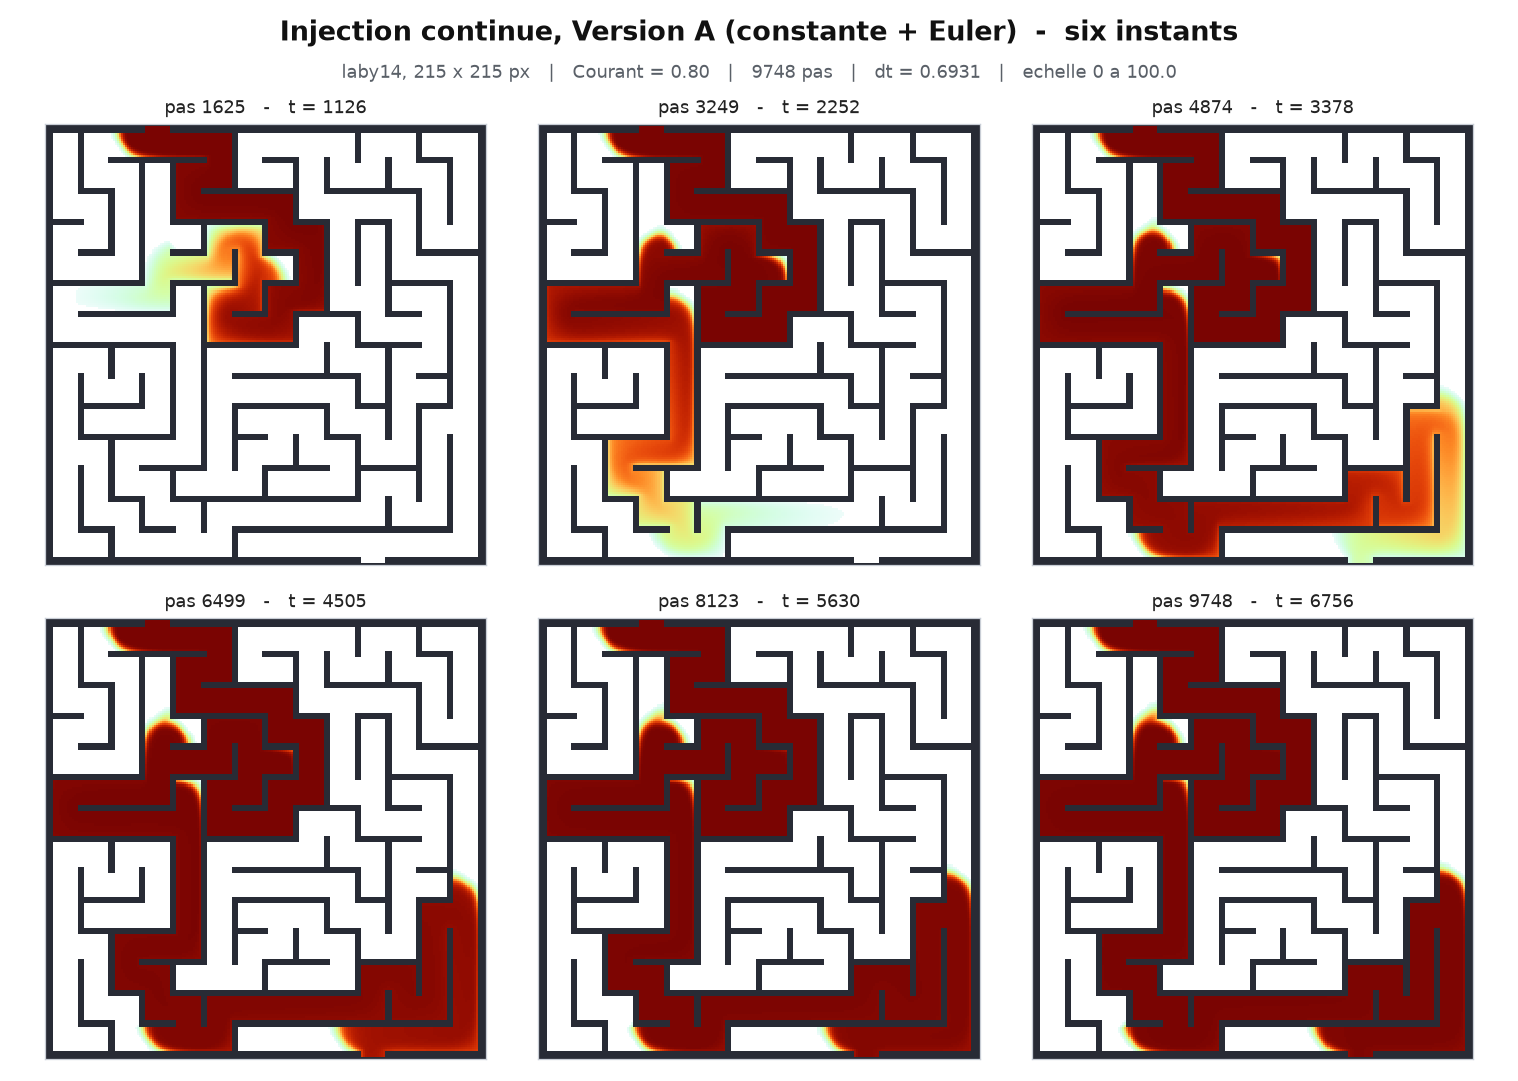

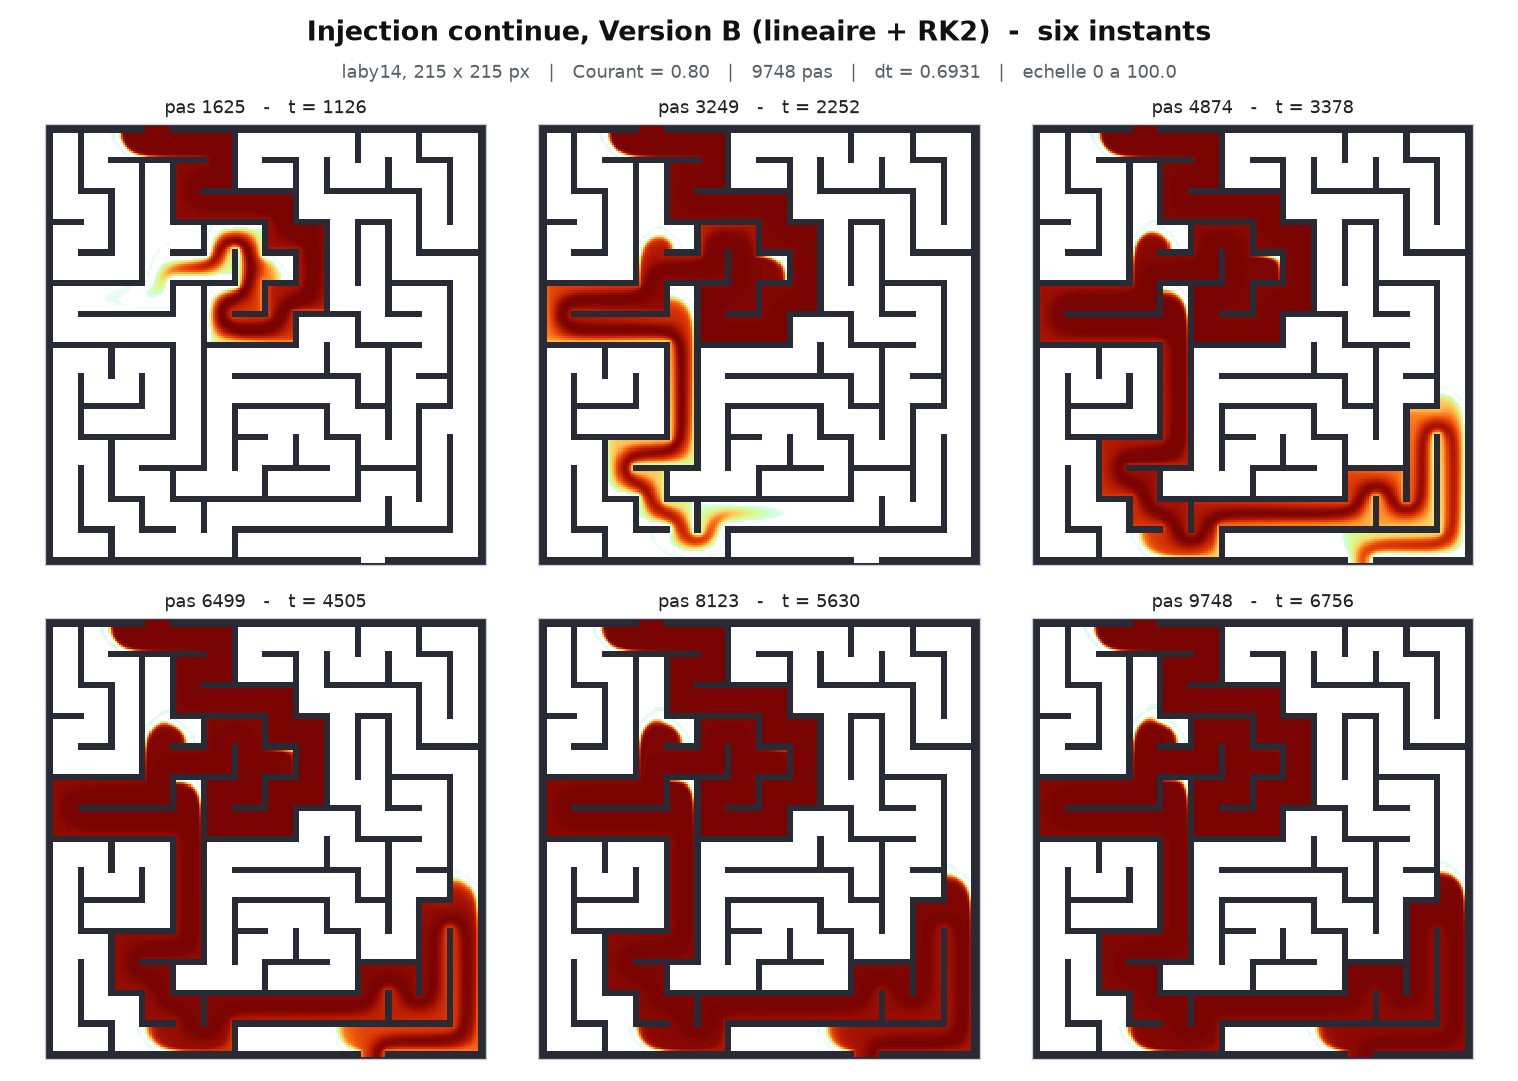

In [14]:
if RELANCER:
    F.figures("laby14")

for nom in ("fig1_injection_A_6_instants",
            "fig1_injection_B_6_instants"):
    display(Image(os.path.join("resultats", nom + ".png"), width=980))

**Ce qu'on voit sur l'injection continue.**

L'encre entre par le haut, remplit les couloirs, explore les embranchements et finit par
relier l'entrée à la sortie. **Le labyrinthe est résolu sans qu'aucun algorithme de
recherche de chemin n'ait été écrit** : c'est l'écoulement qui trouve la sortie, parce
qu'il n'existe qu'un seul trajet permettant au débit de passer de l'entrée à la sortie.

En comparant A et B au même instant, on constate que le front est **au même endroit** —
les deux schémas transportent à la bonne vitesse — mais que le front de A est plus
**flou**. C'est la diffusion numérique.

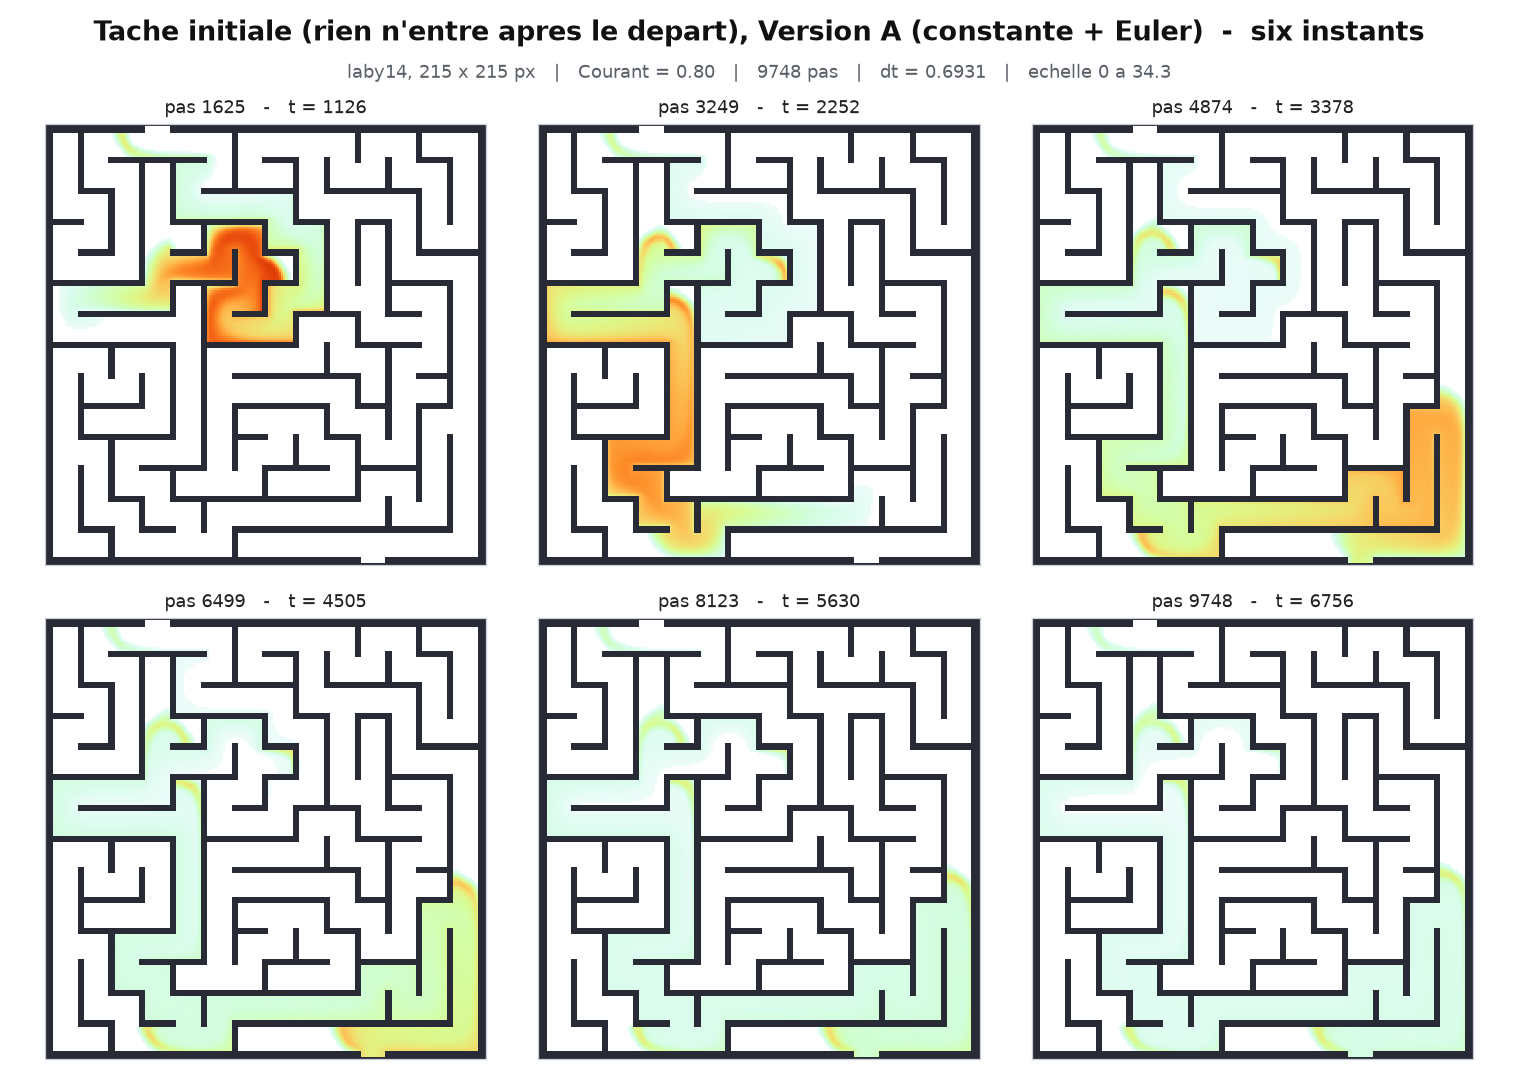

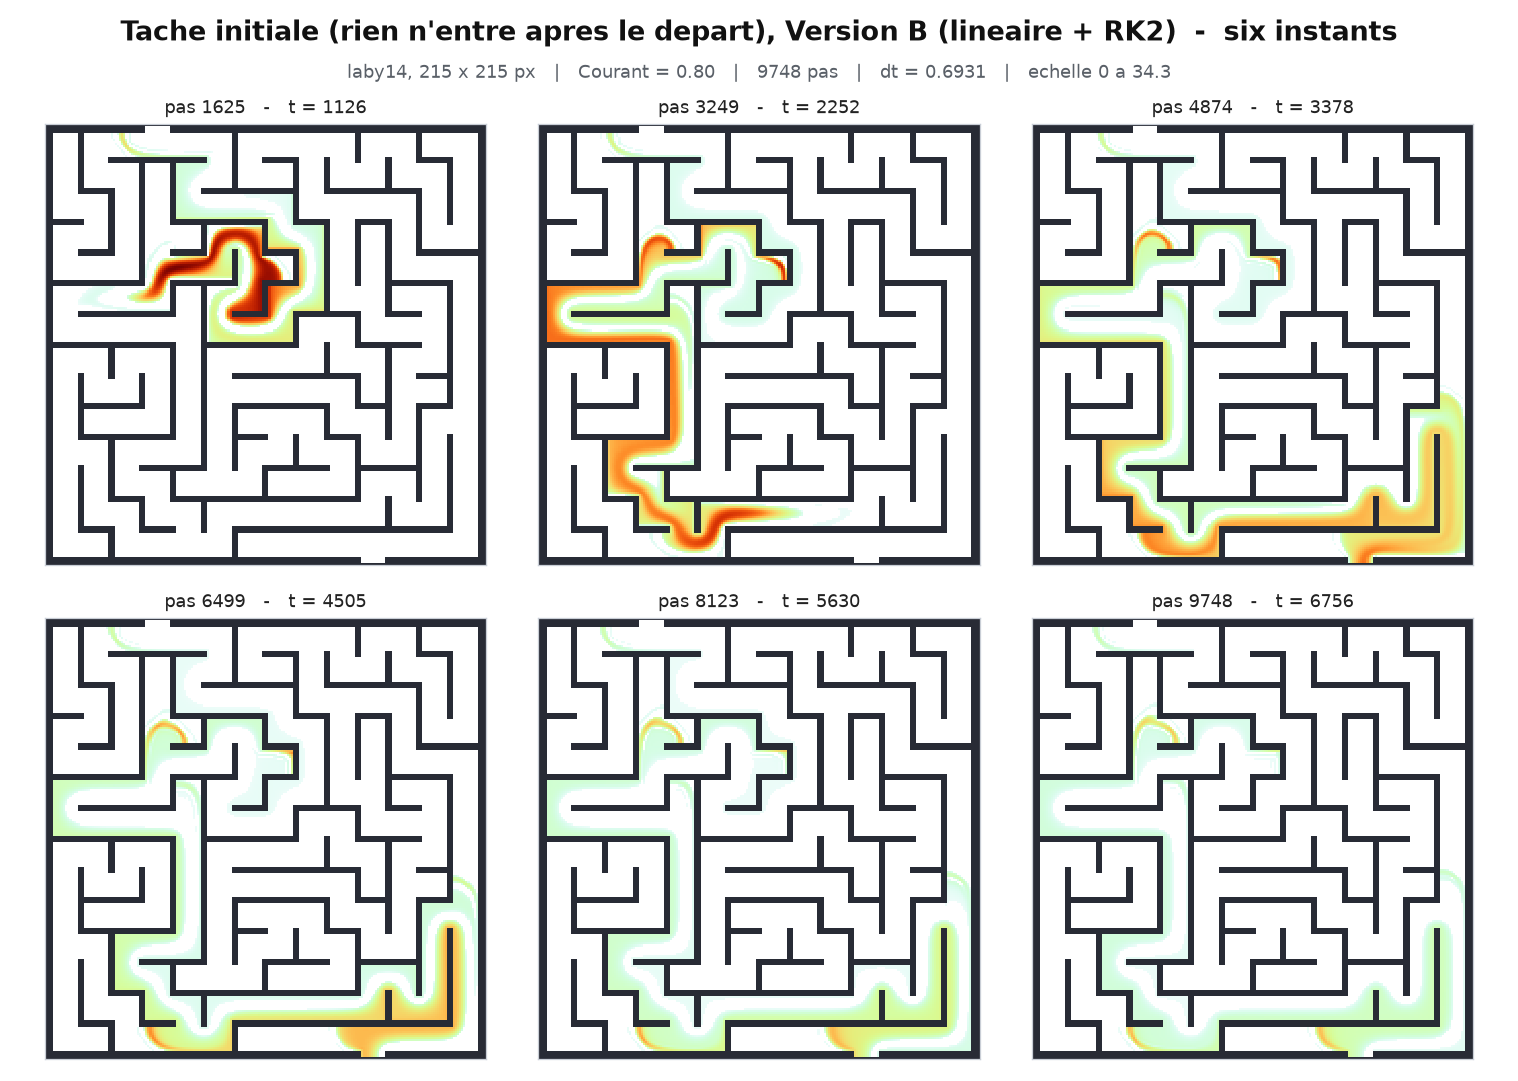

In [15]:
for nom in ("fig1_tache_A_6_instants",
            "fig1_tache_B_6_instants"):
    display(Image(os.path.join("resultats", nom + ".png"), width=980))

**Ce qu'on voit sur la tache initiale.**

La tache part de l'entrée, suit le même chemin, et s'**étale** en avançant. Cet
étalement est intégralement numérique, puisqu'il n'y a aucune diffusion physique dans le
modèle. Il est nettement plus fort en version A qu'en version B.

À la fin, la tache est presque entièrement sortie du domaine : c'est pour cela que
l'échelle de couleur est adaptée, sinon les dernières images seraient blanches.

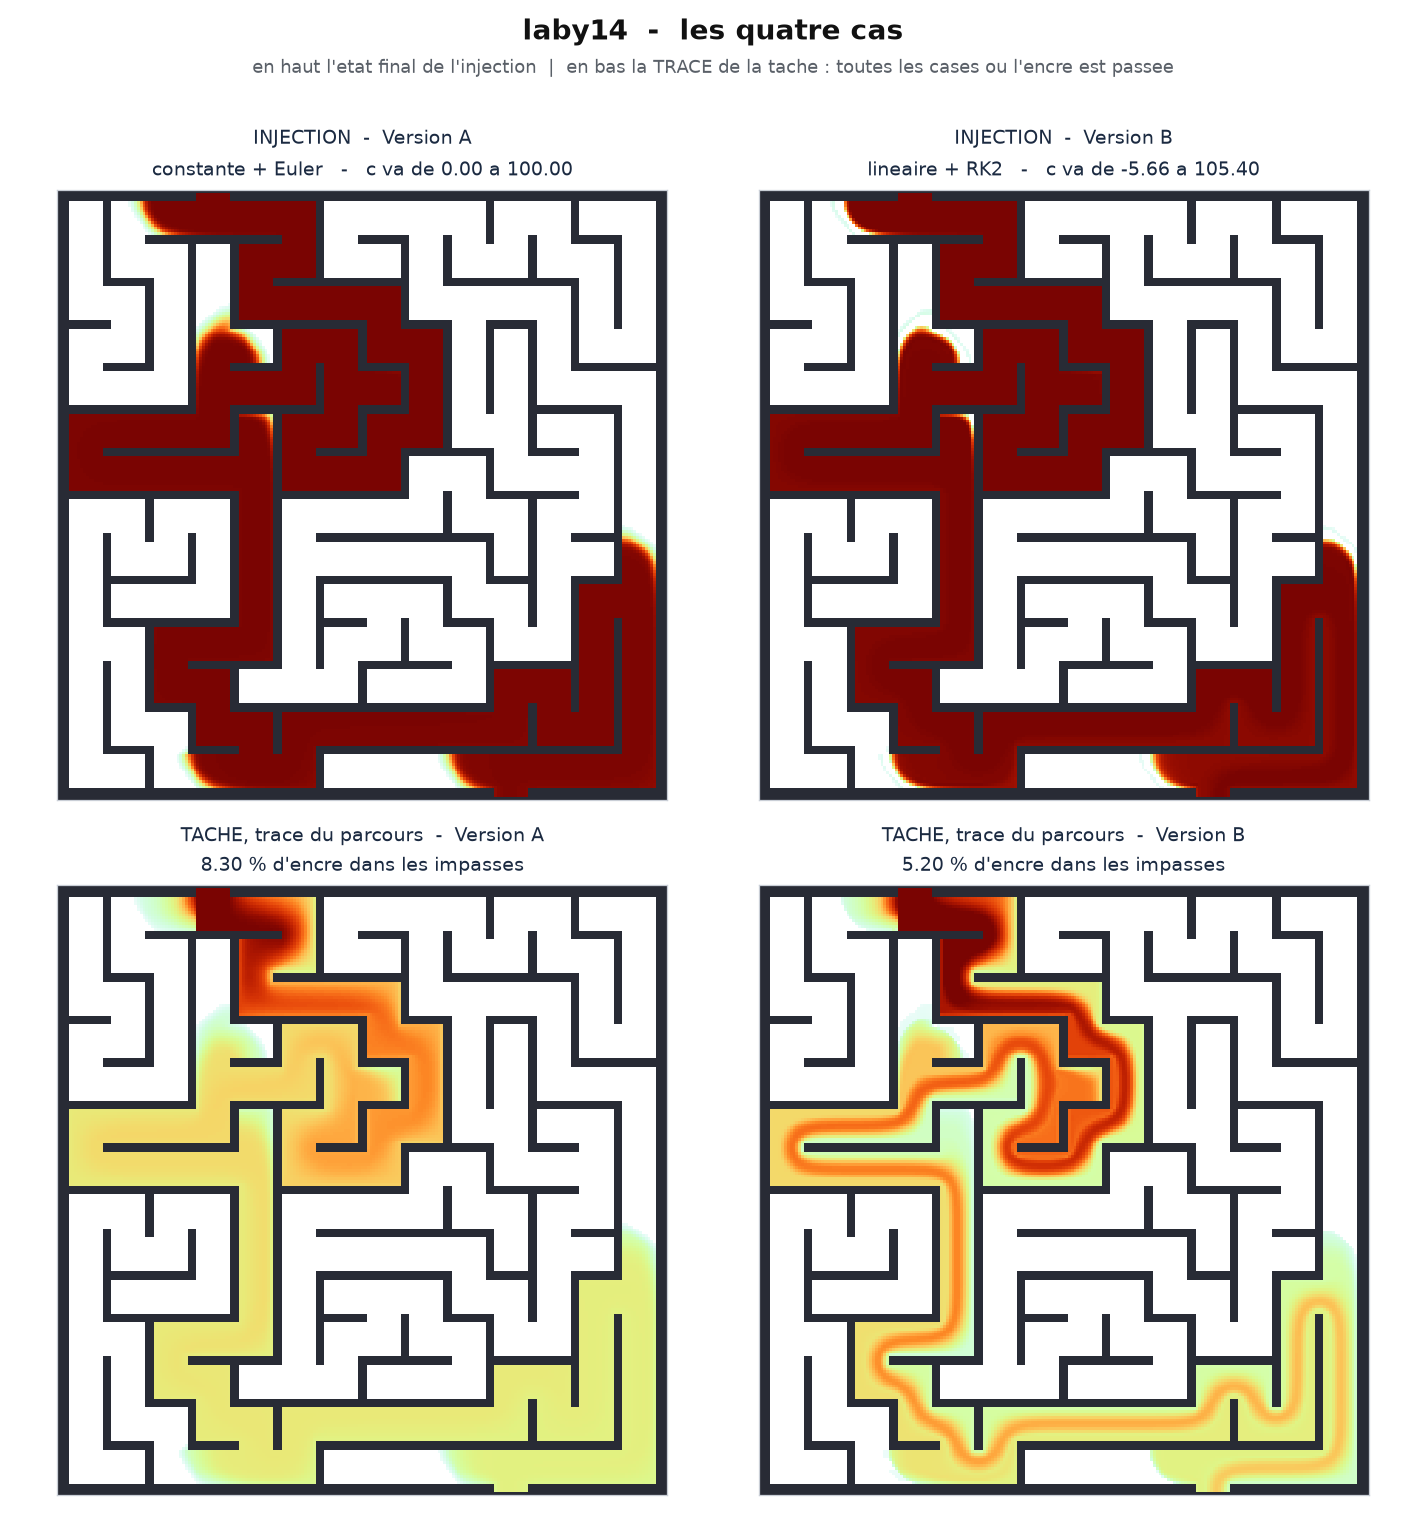

In [16]:
display(Image(os.path.join("resultats", "fig2_quatre_cas.png"), width=940))

**La figure de synthèse.** En haut, l'état **final** de l'injection pour les deux versions.
En bas, la **trace** de la tache : le maximum atteint par la concentration dans chaque
maille depuis le début, c'est-à-dire toutes les cases où l'encre est passée.

La trace est le meilleur révélateur de la diffusion numérique : en version A, elle
« bave » dans les impasses ; en version B, elle dessine un chemin net.

## 3.5 Les vidéos

Les figures montrent six instants. Les vidéos en montrent **240**, et surtout la vidéo
`A_contre_B.mp4` fait ce qu'aucune figure fixe ne peut faire correctement : montrer les
deux schémas **au même instant, côte à côte**, sur toute la durée.

Les deux versions y avancent dans la **même boucle**, avec le même $\Delta t$ et le même
nombre de pas. Tout ce qui les distingue à l'écran vient donc du schéma, et de rien
d'autre.

*Si la vidéo ne s'affiche pas dans votre lecteur de notebook, les fichiers sont dans
`resultats/` et s'ouvrent avec n'importe quel lecteur.*

In [17]:
if RELANCER:
    F.videos("laby14")

display(Video(os.path.join("resultats", "A_contre_B.mp4"), embed=False, width=880))

In [18]:
display(Video(os.path.join("resultats", "injection_B.mp4"), embed=False, width=620))

---
# Partie 4 — Analyse critique

**Objectif :** expliquer l'écart de comportement entre les deux versions, en mesurer les
conséquences, et délimiter ce que ce modèle ne sait pas faire.

Cette partie ne présente pas de nouveaux calculs : elle établit ce que les résultats
précédents valent, et ce qu'ils ne valent pas.

## 4.1 Pourquoi A étale et B reste net : la mesure des poids du schéma

Sur les figures, les deux versions transportent l'encre **à la même vitesse** — le front
est au même endroit au même instant — mais celui de A est flou et celui de B est net.
D'où vient cette différence, puisque la vitesse est la même ?

On peut répondre sans aucune théorie, en **mesurant** ce que chaque schéma fait.

**L'expérience.** Je lâche **un seul pic** d'encre dans une case, tout le reste à zéro, et
je fais **un seul pas**. Les valeurs obtenues sont alors directement les **poids** avec
lesquels le schéma redistribue le contenu d'une case vers ses voisines.

C'est le principe d'une goutte de colorant : on en met une seule, on mélange une fois, et
on lit la recette dans ce qui ressort.

In [19]:
# Un pic unique dans un couloir droit, un seul pas. Les valeurs obtenues
# SONT les coefficients avec lesquels le schema redistribue une case.
n, k = 41, 20
canal = np.zeros((3, n)); canal[1, :] = 1.0
u_c = np.zeros((3, n - 1)); u_c[1, :] = 1.0
v_c = np.zeros((2, n))
dt_c = 0.5                      # nombre de Courant = 0,5

def poids(lineaire, schema):
    c = np.zeros((3, n)); c[1, k] = 1.0
    avance = A.pas_euler if schema == "euler" else A.pas_rk2
    return avance(c, canal, u_c, v_c, dt_c, lineaire)[1, :]

pA = poids(False, "euler")      # version A
pB = poids(True, "rk2")         # version B

print("  position        " + "".join("%8d" % d for d in range(-2, 4)))
print("  VERSION A       " + "".join("%8.3f" % v for v in pA[k - 2:k + 4]))
print("  VERSION B       " + "".join("%8.3f" % v for v in pB[k - 2:k + 4]))
print()
print("  somme des poids      A = %.4f     B = %.4f" % (pA.sum(), pB.sum()))
print("  un poids negatif ?   A : %s         B : %s"
      % ("non" if pA.min() >= -1e-12 else "oui",
         "non" if pB.min() >= -1e-12 else "OUI, %.3f" % pB.min()))

  position              -2      -1       0       1       2       3
  VERSION A          0.000   0.000   0.500   0.500   0.000   0.000
  VERSION B          0.008  -0.078   0.617   0.406   0.117  -0.078

  somme des poids      A = 1.0000     B = 1.0000
  un poids negatif ?   A : non         B : OUI, -0.078


### Lecture : un pas de la version A est **une moyenne**

Les deux poids valent `0,500` et `0,500`. Vu depuis la case qui reçoit, cela s'écrit :

$$c_i^{\,n+1} = \tfrac{1}{2}\,c_i^{\,n} + \tfrac{1}{2}\,c_{i-1}^{\,n}$$

La nouvelle valeur d'une case est **la moyenne** entre elle-même et sa voisine amont. Or
faire la moyenne de deux voisines, c'est exactement l'opération d'un **filtre de flou**.
Appliquée une fois elle ne se voit pas ; appliquée 9 748 fois, elle efface tout.

Et cela explique du même coup pourquoi A ne sort **jamais** de $[0\,;100]$ : une moyenne
de deux nombres est toujours comprise entre les deux. **Une moyenne ne peut pas inventer
un nouvel extrême.**

### Lecture : la version B contient un poids **négatif**

Un poids positif signifie « je donne de l'encre à cette case ». Un poids négatif signifie
« j'en **retire** à cette case ».

B ne se contente donc pas de répartir : elle **creuse** autour du front. C'est l'opération
inverse du flou — c'est le curseur « accentuation » d'un logiciel de photo.

> **Un seul mécanisme, deux conséquences.** B reste net *parce qu'*elle a un coefficient
> négatif, et B produit des concentrations impossibles *parce qu'*elle a un coefficient
> négatif. Retirer de l'encre à une case qui n'en a presque pas la rend négative.

### Et la vitesse, alors ? Séparons les deux choses

In [20]:
x = np.arange(n) - k
print("  %-28s %12s %12s" % ("", "version A", "version B"))
print("  " + "-" * 54)
for ordre, (nom, sens) in enumerate(
        [("centre de gravite", "ou va l'encre  ->  LA VITESSE"),
         ("etalement", "de combien ca bave  ->  LE FLOU"),
         ("asymetrie", "vaguelettes  ->  LES OSCILLATIONS")], start=1):
    va = (pA * (x - 0.5) ** ordre).sum()
    vb = (pB * (x - 0.5) ** ordre).sum()
    print("  moment %d : %-17s %12.4f %12.4f" % (ordre, nom, va, vb))
print()
print("  %-28s %12s %12s" % ("", "version A", "version B"))
etal_A = (pA * (x - 0.5) ** 2).sum()
etal_B = (pB * (x - 0.5) ** 2).sum()
print("  largeur du flou apres %d pas  %9.1f    %9.1f  cases"
      % (n_pas, np.sqrt(max(etal_A, 0) * n_pas), np.sqrt(max(etal_B, 0) * n_pas)))

                                  version A    version B
  ------------------------------------------------------
  moment 1 : centre de gravite       0.0000       0.0000
  moment 2 : etalement               0.2500       0.0000
  moment 3 : asymetrie               0.0000      -0.3750

                                  version A    version B
  largeur du flou apres 9748 pas       49.4          0.0  cases


### Ce que ces trois nombres disent

Le paquet de poids a deux propriétés **indépendantes** :

- **où se trouve son centre** dit où part l'encre → c'est **la vitesse** ;
- **à quel point il est étalé** dit de combien ça bave → c'est **le flou**.

Les deux versions ont **exactement le même centre**. Même vitesse, aucun retard, aucune
avance : c'est pour cela que les fronts sont au même endroit sur les figures. Ce qui
diffère, c'est l'**étalement** — et c'est là que tout se joue.

Rapporté aux 9 748 pas du labyrinthe, cet étalement s'accumule sur des dizaines de
mailles pour la version A. Un couloir ne fait que 12 pixels de large : voilà pourquoi
l'encre de A déborde dans les impasses.

**Mais B n'est pas parfaite pour autant.** Son étalement est nul, et pourtant son
**asymétrie** ne l'est pas. L'erreur n'a pas disparu : elle a **changé de nature**, du
flou vers les vaguelettes. Ce sont elles, les concentrations négatives.

| | se trompe sur | effet visible | parité |
|---|---|---|---|
| Version A | l'étalement (moment 2) | **diffusion** : ça floute | paire |
| Version B | l'asymétrie (moment 3) | **dispersion** : ça oscille | impaire |

On retrouve la règle de symétrie : dérivée paire $\Rightarrow$ diffusion, dérivée impaire
$\Rightarrow$ oscillation.

### Origine de cette diffusion

Ces mesures sont la lecture concrète d'un résultat établi. En advection, la stabilité du
schéma exige que le flux d'un bord soit **décentré vers l'amont**, c'est-à-dire pris du
côté d'où vient le fluide :

$$F = \frac{a + |a|}{2}\,c_{\text{gauche}} + \frac{a - |a|}{2}\,c_{\text{droite}}$$

où $a$ est la vitesse normale à la face considérée, $c_{\text{gauche}}$ et
$c_{\text{droite}}$ les deux valeurs proposées par les mailles situées de part et d'autre,
et $F$ le flux finalement retenu. La construction n'est qu'un interrupteur : si $a > 0$ le
second terme s'annule et seule la maille amont compte ; si $a < 0$ c'est l'inverse.

Ce décentrement est indispensable, mais il n'est pas gratuit : il fait apparaître dans
l'équation résolue un terme de diffusion que personne n'a demandé,

$$\varepsilon = \frac{u\,\Delta x}{2}\,(1-\nu)$$

**et ce $\varepsilon$ est précisément l'étalement que je viens de mesurer.** Deux
conséquences vérifiables dans ce notebook :

- $\varepsilon \to 0$ quand $\nu \to 1$ : à Courant 1, la case se vide **entièrement**
  dans la suivante, il ne reste rien à remoyenner. C'est le **test 2** du canal, où la
  translation est exacte à $0{,}00\times10^{0}$ près ;
- $\varepsilon \propto \Delta x$ : raffiner divise la diffusion, ce que mesure le **test
  de convergence** de la partie 2.2.

## 4.2 Les impasses comme instrument de mesure

Le labyrinthe généré est *parfait* : il existe un unique chemin entre deux cases, aucune
boucle, et donc un grand nombre d'impasses. Cette propriété, choisie délibérément, fournit
un critère de mesure.

Considérons une impasse, c'est-à-dire un sous-domaine $\Omega_{\text{imp}}$ relié au reste
du labyrinthe par une seule section $S$. Le fluide étant incompressible et l'écoulement
permanent, la masse contenue dans $\Omega_{\text{imp}}$ est constante, donc le débit net à
travers $S$ est nul :

$$\int_{S} \vec{V}\cdot\vec{n}\, dS = 0$$

$S$ étant l'unique frontière ouverte, et l'écoulement potentiel ne présentant pas de
recirculation, il en résulte $\vec{V} = \vec{0}$ dans toute l'impasse.

Or le constituant est **purement advecté** : son seul mécanisme de transport est le champ
de vitesses. Une vitesse nulle implique donc un flux nul, et par conséquent qu'aucune
concentration ne peut pénétrer dans l'impasse.

La concentration qui s'y trouve néanmoins ne peut provenir que du schéma numérique
lui-même. Elle constitue une mesure directe de la **diffusion numérique**, indépendante de
toute solution de référence, et permet de comparer objectivement les deux versions.

In [21]:
print("encre arrivee dans les impasses, la ou l'eau est a l'arret")
print()
print("%-12s %14s %14s %12s" % ("cas", "version A", "version B", "reduction"))
print("-" * 56)
for cas in ("injection", "tache"):
    a = mesures["%s_A" % cas][2]
    b = mesures["%s_B" % cas][2]
    print("%-12s %13.2f %% %13.2f %% %10.0f %%"
          % (cas, a, b, 100.0 * (a - b) / a))
print()
print("La version lineaire + RK2 reduit nettement la diffusion numerique.")
print("C'est une mesure, pas une impression visuelle.")

encre arrivee dans les impasses, la ou l'eau est a l'arret

cas               version A      version B    reduction
--------------------------------------------------------
injection             0.20 %          0.13 %         32 %
tache                 8.30 %          5.20 %         37 %

La version lineaire + RK2 reduit nettement la diffusion numerique.
C'est une mesure, pas une impression visuelle.


## 4.3 Les dépassements de la version B, et le théorème de Godunov

La version B est plus précise. Elle a pourtant un défaut que la version A n'a pas, et ce
défaut n'est **pas un bug**.

In [22]:
print("bornes atteintes par la concentration, injection continue")
print("   (la valeur injectee est 100, aucune concentration physique ne peut")
print("    sortir de l'intervalle [0 ; 100])")
print()
for version in ("A", "B"):
    c_min, c_max, _ = mesures["injection_%s" % version]
    etat = "dans [0 ; 100]" if (c_min >= -1e-9 and c_max <= 100 + 1e-9) else "DEBORDE"
    print("   version %s :  c va de %8.2f a %8.2f    ->  %s"
          % (version, c_min, c_max, etat))

bornes atteintes par la concentration, injection continue
   (la valeur injectee est 100, aucune concentration physique ne peut
    sortir de l'intervalle [0 ; 100])

   version A :  c va de     0.00 a   100.00    ->  dans [0 ; 100]
   version B :  c va de    -5.66 a   105.40    ->  DEBORDE


La version B produit des concentrations **négatives** et des concentrations **supérieures
à la valeur injectée**. Physiquement, cela n'a aucun sens.

### Ce n'est pas une erreur de programmation

C'est une conséquence inévitable du choix d'un ordre élevé, et nous pouvons l'établir à
partir de notre propre mesure de la partie 4.1.

La version A ne redistribue l'encre qu'avec des coefficients **positifs** : chaque nouvelle
valeur est une moyenne pondérée de valeurs existantes, et une moyenne est toujours comprise
entre le minimum et le maximum de ce qu'elle moyenne. La version A ne peut donc
**jamais** créer un extremum nouveau. Mais une moyenne lisse, et c'est précisément ce qui
la limite à l'ordre 1.

Pour dépasser l'ordre 1, il faut au contraire **creuser** autour du front, donc introduire
un coefficient **négatif** — et dès lors, le résultat peut sortir de l'intervalle des
valeurs de départ.

Les deux propriétés sont donc incompatibles.

> **Remarque, en complément du cours.** Ce résultat est connu sous le nom de **théorème de
> Godunov** : aucun schéma *linéaire* d'ordre supérieur à 1 ne peut être *monotone*,
> c'est-à-dire garantir qu'il ne crée pas de nouveaux extrema. Nous ne l'avons pas vu au
> cours ; nous le mentionnons parce qu'il nomme exactement le comportement que nous avons
> mesuré.

Il faut choisir entre deux propriétés qu'on voudrait toutes les deux :

| | Version A | Version B |
|---|---|---|
| Ordre | 1 | 2 |
| Monotone | **oui** | non |
| Diffusion numérique | forte | faible |
| Dépassements | aucun | oui |

Il n'existe donc **pas de « meilleur » schéma** dans l'absolu. Le choix dépend de l'usage
que l'on fait du résultat :

- si la grandeur transportée doit rester physique à tout prix (une concentration qui
  alimente une réaction chimique, une fraction qui doit rester entre 0 et 1), **A** ;
- si on veut la position et la netteté du front, **B**.

### Comment on sortirait de ce dilemme

L'incompatibilité ne vaut que pour les schémas **linéaires**, c'est-à-dire ceux dont les
coefficients de redistribution sont fixés une fois pour toutes. Si l'on autorise ces
coefficients à dépendre de la solution elle-même, le raisonnement précédent ne s'applique
plus.

C'est l'idée des *limiteurs de pente* : réduire la pente reconstruite là où la solution
varie brutalement, et la laisser intacte là où elle est régulière. On obtiendrait alors
l'ordre 2 dans les zones lisses **et** l'absence de dépassement près des fronts raides.

Cela n'a pas été réalisé ici, et ne faisait pas partie de la demande.

## 4.4 Les limites de ce travail

Être critique, c'est aussi dire ce que le modèle ne sait pas faire.

**1. L'ordre 2 n'est garanti que sur des solutions régulières.** La mesure de la partie 2.2
utilise une gaussienne. Sur un créneau, le développement de Taylor ne s'applique plus et
les deux versions retomberaient à un ordre proche de 1. L'injection continue, dont le front
est raide, est justement un cas défavorable : l'ordre 2 n'y est pas pleinement atteint.

**2. Il n'y a aucune diffusion physique.** C'est conforme à l'énoncé, mais cela veut dire
que le modèle ne représente pas un vrai traceur dans un vrai fluide, qui diffuserait
réellement. Pour cela il faudrait ajouter un terme $D\nabla^2 c$ — et, cette fois,
**additionner** deux voisins.

**3. L'écoulement est permanent.** Le champ de vitesses ne change jamais, ce qui permet de
calculer $\Delta t$ une seule fois. En instationnaire, il faudrait le recalculer à chaque
pas.

**4. Le maillage est imposé par l'image.** Une maille = un pixel. On ne peut pas raffiner
localement autour du front sans changer l'image de départ.

**5. La validation porte sur un canal droit.** Les tests de la partie 2 valident le moteur
sur une géométrie simple. Sur le labyrinthe, la seule vérification disponible est globale
(bilan de masse, débit entrée = sortie), faute de solution exacte à laquelle comparer.

---
# Conclusion

**Ce qui a été construit.** Un solveur d'advection 2D par volumes finis, en deux versions
(reconstruction constante + Euler, reconstruction linéaire + Runge-Kutta 2), appliqué à un
champ de vitesses irrotationnel obtenu par différences finies.

**Ce qui a été validé, et comment.**

| Propriété | Comment | Résultat |
|---|---|---|
| Conservation de la masse | bilan sur la tache initiale | écart $\sim 10^{-12}$ |
| Cohérence du champ de vitesses | débit entrant contre débit sortant | écart relatif $\sim 10^{-11}$ |
| Précision des vitesses | développement de Taylor + mesure | ordre 2 |
| Ordre des schémas | convergence sur solution exacte | A $\approx$ 1, B $\approx$ 2 |
| Translation exacte à $\nu = 1$ | canal rectiligne | écart $< 10^{-10}$ |
| Imperméabilité des murs | canal rectiligne | aucune fuite |
| Reproductibilité | recalcul comparé aux résultats enregistrés | 0,000e+00 |

**Ce qui a été appliqué.** Le labyrinthe est résolu : l'injection continue trace
elle-même le chemin de l'entrée à la sortie, sans aucun algorithme de recherche de chemin.

**Ce que nous en retenons.** Il n'existe pas de meilleur schéma. La version A est moins
précise mais reste en tout point physique ; la version B est plus précise mais produit des
concentrations impossibles. Ce compromis n'est pas un défaut d'implémentation : il tient à
ce que les coefficients de redistribution du schéma sont fixés d'avance. Rendre ces
coefficients dépendants de la solution elle-même — c'est le principe des limiteurs de
pente — permettrait d'obtenir à la fois la netteté de la version B et le caractère
physique de la version A, mais sort du cadre de ce travail.

---

### Références

Les notions utilisées dans ce document — méthode des résidus pondérés et formulation en
volumes finis, reconstruction constante et linéaire, décentrement amont, condition limite
faible, condition de Courant en deux dimensions — proviennent du cours de méthodes
numériques linéaires en génie civil et géologique (ULiège, ArGEnCo, année 2026-2027).

### Contenu du dépôt

    src/vitesses.py                          potentiel -> vitesses aux faces, conditions aux limites
    src/advection.py                         flux, bilan, pas de temps, Euler et RK2
    src/simulation_labyrinthe.py             les quatre cas, en parallèle
    src/figures.py                           toutes les figures et les vidéos
    src/genere_labyrinthe.py                 génération déterministe du labyrinthe
    src/test_advection_canal_rectiligne.py   les tests du canal
    src/test_convergence.py                  la mesure de l'ordre
    laplace_prof/                            le solveur fourni, non modifié
    data/                                    images et champs de potentiel
    resultats/                               tout est produit par du code de src/